In [1]:
import mne
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import linregress
import pandas as pd
from pathlib import Path
from tqdm import tqdm
import warnings
import sys

sys.path.append('/Users/qmoreau/Documents/ERN_sim/lagged_hilbert_autocoherence/python')
from woody_filter import woody, woody_stochastic
from lagged_autocoherence import lagged_hilbert_autocoherence

warnings.filterwarnings('ignore')

data_dir = Path('/Users/qmoreau/Documents/Work/flanker_bursts/PreprocessedData/ernpipeline/')

subjects = [
    'sub-AG05AS29', 'sub-AH17AR05', 'sub-AL07NK06', 'sub-AL08AS02', 'sub-AR06AS06',
    'sub-AR10IO04', 'sub-AT06ED25', 'sub-AU09GE22', 'sub-CH04ER19', 'sub-CH05NK28',
    'sub-CH06UT07', 'sub-CH07AD15', 'sub-CH09AS13', 'sub-CK04NS18', 'sub-CK06ED08',
    'sub-CK06ST11', 'sub-CK06US15', 'sub-DADARE11', 'sub-DT05EV26', 'sub-DT07ES22',
    'sub-DTINTZ10', 'sub-EK05AN14', 'sub-EK06ER26', 'sub-EK07CH24', 'sub-EL05JO26',
    'sub-EL06LD17', 'sub-EL07EL14', 'sub-EN04ER01', 'sub-EN05AN02', 'sub-EN05KT02',
    'sub-EN05US05', 'sub-EN06AN21', 'sub-EN08CH27', 'sub-EP05EN09', 'sub-ER03ER09',
    'sub-ER04ER12', 'sub-ER04RT24', 'sub-ER05AN13', 'sub-ER05AV01', 'sub-ER05EL09',
    'sub-ER05EL26', 'sub-ER05ER07', 'sub-ER05IM29', 'sub-ER05MA17', 'sub-ER05NG11',
    'sub-ER05RK06', 'sub-ER05RT24', 'sub-ER06EL06', 'sub-ER06EN27', 'sub-ER06ET15',
    'sub-ER06IS22', 'sub-ER06US24', 'sub-ER07AN28', 'sub-ER07AS24', 'sub-ER07EF15',
    'sub-ER07EL10', 'sub-ER07ER23', 'sub-ER07ER30', 'sub-ER07RL02', 'sub-ER08AS28',
    'sub-ER08EN05', 'sub-ER09NK30', 'sub-ES06ER27', 'sub-ES06NK11', 'sub-EZ04SE15',
    'sub-GA04LI18', 'sub-HEERLD19', 'sub-IA05NS20', 'sub-ID07EN28', 'sub-IG06AI28',
    'sub-IG06LF01', 'sub-IG06NS07', 'sub-IG06WE03', 'sub-IG07RT16', 'sub-IK06ET06',
    'sub-IK09LD05', 'sub-IN05ED23', 'sub-IN06AS14', 'sub-IS06RG09', 'sub-IT08ND26',
    'sub-JU05IN24', 'sub-KA04LF11', 'sub-KE05AN23', 'sub-KE07AN05', 'sub-KE07ER04',
    'sub-KE08AS23', 'sub-KN05EN09', 'sub-KO07EL16', 'sub-LA08RE26', 'sub-LO06RE10',
    'sub-LY07EL23', 'sub-MA06LO21', 'sub-ME05NS04', 'sub-NA04AV25', 'sub-ND05NG06',
    'sub-ND06EF01', 'sub-NE06AS01', 'sub-NE06EL01', 'sub-NG03YI17', 'sub-NG06EA08',
    'sub-NK06AS24', 'sub-NK06RG30', 'sub-NN04AN24', 'sub-NN05AN05', 'sub-NN05IR17',
    'sub-NN06TH16', 'sub-NN07EN14', 'sub-NN07ID18', 'sub-NN08AS03', 'sub-NN08EL29',
    'sub-NN08ER22', 'sub-NN08LM06', 'sub-NN09LM18', 'sub-NN09NS31', 'sub-NO05RT22',
    'sub-NS09EL05', 'sub-NY04DT26', 'sub-NZ04EN16', 'sub-NZ09ER04', 'sub-OH05NK29',
    'sub-ON05EL22', 'sub-OW07RK26', 'sub-PP07AS29', 'sub-RASUAN07', 'sub-RF09EL18',
    'sub-RG05RS16', 'sub-RG06AS09', 'sub-RO06AN18', 'sub-RT07LD06', 'sub-RYRAAN26',
    'sub-RZ05ND19', 'sub-SA05AH22', 'sub-SE05AS26', 'sub-SE05ZI24', 'sub-SE06AM29',
    'sub-SE06NS17', 'sub-ST03ED03', 'sub-ST07NK15', 'sub-TA03RL11', 'sub-TE05AS09',
    'sub-TE05NS01', 'sub-TE10AN12', 'sub-TH07AR12', 'sub-TH08ER21', 'sub-TT06LF28',
    'sub-TT08NS17', 'sub-TZ08US31', 'sub-US07US10', 'sub-US08KE27', 'sub-VA05AS27',
    'sub-VA05OR26', 'sub-VA06NZ29', 'sub-VA06OV12', 'sub-WA04EJ22', 'sub-WA05EJ08',
    'sub-XX04AS28'
]

In [35]:
def align_trials(trials, lags):
    n_trials, n_times = trials.shape
    aligned = np.zeros_like(trials)
    for i in range(n_trials):
        lag = lags[i]
        if lag > 0:
            aligned[i, :] = np.concatenate([trials[i, lag:], np.zeros(lag)])
        elif lag < 0:
            aligned[i, :] = np.concatenate([np.zeros(-lag), trials[i, :lag]])
        else:
            aligned[i, :] = trials[i, :]
    return aligned

def reinstate_lags(trials, lags):
    n_trials, n_times = trials.shape
    unaligned = np.zeros_like(trials)
    for i in range(n_trials):
        lag = lags[i]
        if lag > 0:
            unaligned[i, :] = np.concatenate([np.zeros(lag), trials[i, :-lag]])
        elif lag < 0:
            unaligned[i, :] = np.concatenate([trials[i, -lag:], np.zeros(-lag)])
        else:
            unaligned[i, :] = trials[i, :]
    return unaligned

def regress_erp(trials, erp):
    regressed = np.zeros_like(trials)
    for i in range(trials.shape[0]):
        slope, intercept, _, _, _ = linregress(erp, trials[i, :])
        regressed[i, :] = trials[i, :] - (intercept + slope * erp)
    return regressed

def compute_tfr(trials, freqs, sfreq):
    n_trials, n_times = trials.shape
    n_cycles = freqs / 2.0
    tfr = np.zeros((len(freqs), n_times))
    for trial in range(n_trials):
        for idx, (freq, n_cycle) in enumerate(zip(freqs, n_cycles)):
            wavelet_duration = min(3 * n_cycle / freq, 0.5)
            wavelet_time = np.arange(-wavelet_duration, wavelet_duration, 1/sfreq)
            wavelet = np.exp(2j * np.pi * freq * wavelet_time) * np.exp(-wavelet_time**2 / (2 * (n_cycle / (2*np.pi*freq))**2))
            convolved = np.convolve(trials[trial, :], wavelet, mode='same')
            tfr[idx, :] += np.abs(convolved) ** 2
    return tfr / n_trials

def baseline_correct(tfr, times, bl_window=(-0.5, 0)):
    bl_mask = (times >= bl_window[0]) & (times <= bl_window[1])
    bl = tfr[:, bl_mask].mean(axis=1, keepdims=True)
    return ((tfr - bl) / bl) * 100

def extract_theta(tfr_pct, freqs, times, theta_range=(4, 8), time_window=(0, 0.5)):
    theta_mask = (freqs >= theta_range[0]) & (freqs <= theta_range[1])
    time_mask = (times >= time_window[0]) & (times <= time_window[1])
    return tfr_pct[theta_mask, :][:, time_mask].mean()

In [67]:
def analyze_subject(epochs_path, trial_type='incorrect', channel='FZ'):
    epochs = mne.read_epochs(epochs_path, preload=True, verbose=False)

    if trial_type == 'incorrect':
        codes = ['108', '109', '118', '119', '128', '129', '138', '139']
    else:
        codes = ['106', '107', '116', '117', '126', '127', '136', '137']

    epochs_sel = epochs[codes]
    n_trials = len(epochs_sel)
    if n_trials < 5:
        return None

    data = epochs_sel.copy().pick([channel]).get_data()[:, 0, :] * 1e6
    times = epochs_sel.times
    sfreq = epochs_sel.info['sfreq']
    freqs = np.arange(1, 40, 0.25)

    erp = data.mean(axis=0)

    # 1. Classic induced
    tfr_total_classic  = compute_tfr(data,            freqs, sfreq)
    tfr_evoked_classic = compute_tfr(erp[np.newaxis], freqs, sfreq)

    # 2. Woody induced
    _, lags_sw, _ = woody_stochastic(data.T, tol=0.1, max_it=100, n_runs=1000,
                                     max_lag_init=10, xcorr_mthd='unbiased', max_shift=50)
    aligned      = align_trials(data, lags_sw)
    erp_aligned  = aligned.mean(axis=0)
    tfr_total_woody  = compute_tfr(aligned,                 freqs, sfreq)
    tfr_evoked_woody = compute_tfr(erp_aligned[np.newaxis], freqs, sfreq)

    # 3. Regression classic
    residuals       = regress_erp(data, erp)
    tfr_reg_classic = compute_tfr(residuals, freqs, sfreq)

    # 4. Regression woody + reinstate
    residuals_w   = regress_erp(aligned, erp_aligned)
    reinstated    = reinstate_lags(residuals_w, lags_sw)
    tfr_reg_woody = compute_tfr(reinstated, freqs, sfreq)

    return {
        'n_trials':          n_trials,
        'times':             times,
        'freqs':             freqs,
        'erp_raw':   erp,          # data.mean(axis=0)
        'erp_woody': erp_aligned,  # aligned.mean(axis=0)
        'tfr_total_classic': tfr_total_classic,
        'tfr_evoked_classic':tfr_evoked_classic,
        'tfr_total_woody':   tfr_total_woody,
        'tfr_evoked_woody':  tfr_evoked_woody,
        'tfr_reg_classic':           tfr_reg_classic,
        'tfr_reg_woody_reinstate':   tfr_reg_woody,
    }

In [68]:
results_incorrect = []
results_correct = []

for sub_id in tqdm(subjects):
    sub_file = data_dir / sub_id / f'{sub_id}_desc-epochs_eeg.fif'
    if not sub_file.exists():
        continue
    try:
        res_inc = analyze_subject(sub_file, trial_type='incorrect')
        res_cor = analyze_subject(sub_file, trial_type='correct')
        if res_inc:
            res_inc['subject'] = sub_id
            results_incorrect.append(res_inc)
        if res_cor:
            res_cor['subject'] = sub_id
            results_correct.append(res_cor)
    except:
        continue

print(f'Incorrect: {len(results_incorrect)}, Correct: {len(results_correct)}')

100%|██████████| 156/156 [4:45:35<00:00, 109.85s/it]   

Incorrect: 155, Correct: 156


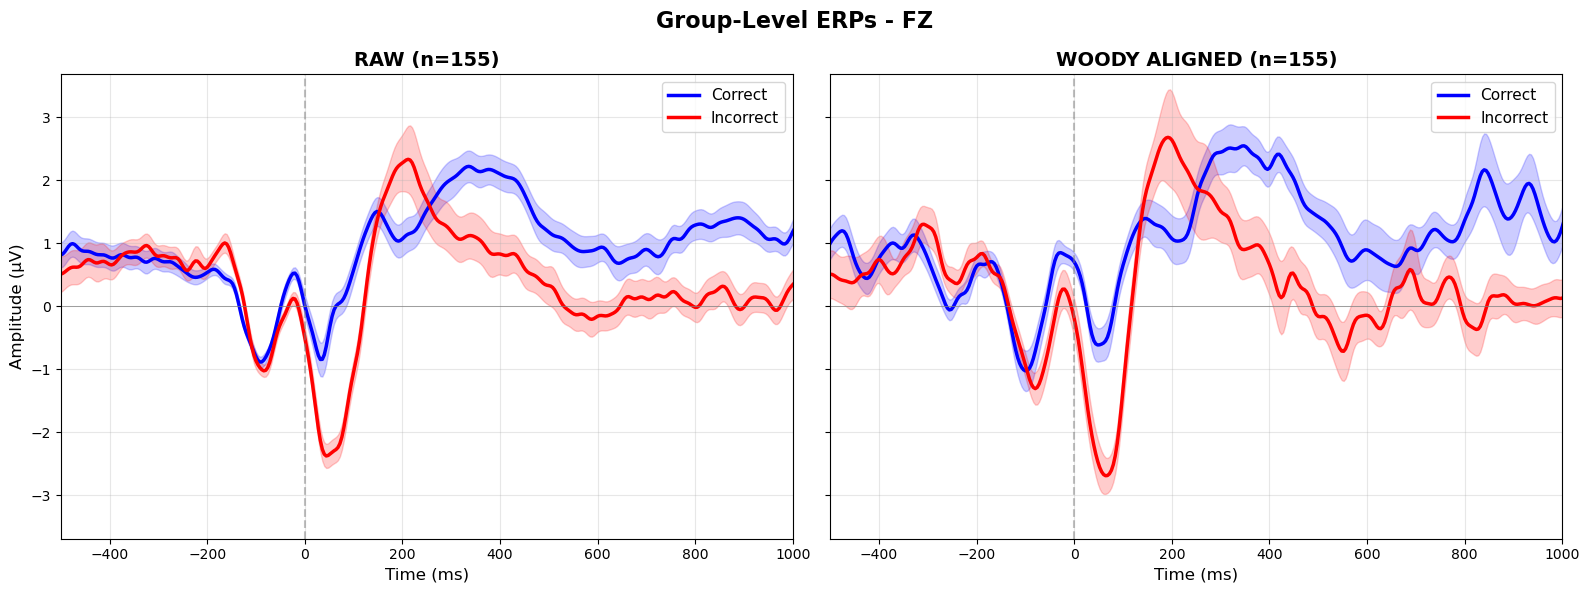

In [69]:
# === COMPUTE GROUP ERP AVERAGES ===
times = results_incorrect[0]['times']

# INCORRECT
inc_erp_all  = np.array([r['tfr_total_classic'] for r in results_incorrect])  # placeholder
# Actually ERPs come from raw trial data - need to recompute or store in analyze_subject
# Add 'erp_raw' and 'erp_woody' to analyze_subject return dict, then:

inc_erp_raw_all   = np.array([r['erp_raw']   for r in results_incorrect])
inc_erp_woody_all = np.array([r['erp_woody']  for r in results_incorrect])
inc_erp_raw_mean  = inc_erp_raw_all.mean(axis=0)
inc_erp_raw_sem   = inc_erp_raw_all.std(axis=0)  / np.sqrt(len(results_incorrect))
inc_erp_woody_mean = inc_erp_woody_all.mean(axis=0)
inc_erp_woody_sem  = inc_erp_woody_all.std(axis=0) / np.sqrt(len(results_incorrect))

# CORRECT
cor_erp_raw_all   = np.array([r['erp_raw']   for r in results_correct])
cor_erp_woody_all = np.array([r['erp_woody']  for r in results_correct])
cor_erp_raw_mean  = cor_erp_raw_all.mean(axis=0)
cor_erp_raw_sem   = cor_erp_raw_all.std(axis=0)  / np.sqrt(len(results_correct))
cor_erp_woody_mean = cor_erp_woody_all.mean(axis=0)
cor_erp_woody_sem  = cor_erp_woody_all.std(axis=0) / np.sqrt(len(results_correct))

# === PLOT: ERPs - RAW vs WOODY (OVERLAID) ===
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6), sharey=True)

all_erps = np.concatenate([inc_erp_raw_mean, cor_erp_raw_mean,
                           inc_erp_woody_mean, cor_erp_woody_mean])
ylim_min = all_erps.min() - 1
ylim_max = all_erps.max() + 1

# Raw
ax1.plot(times * 1000, cor_erp_raw_mean, 'b', linewidth=2.5, label='Correct')
ax1.fill_between(times * 1000, cor_erp_raw_mean - cor_erp_raw_sem,
                 cor_erp_raw_mean + cor_erp_raw_sem, color='b', alpha=0.2)
ax1.plot(times * 1000, inc_erp_raw_mean, 'r', linewidth=2.5, label='Incorrect')
ax1.fill_between(times * 1000, inc_erp_raw_mean - inc_erp_raw_sem,
                 inc_erp_raw_mean + inc_erp_raw_sem, color='r', alpha=0.2)
ax1.axvline(0, color='gray', linestyle='--', alpha=0.5)
ax1.axhline(0, color='gray', linestyle='-', linewidth=0.5)
ax1.set_xlim([-500, 1000])
ax1.set_ylim([ylim_min, ylim_max])
ax1.set_xlabel('Time (ms)', fontsize=12)
ax1.set_ylabel('Amplitude (µV)', fontsize=12)
ax1.set_title(f'RAW (n={len(results_incorrect)})', fontsize=14, fontweight='bold')
ax1.legend(fontsize=11)
ax1.grid(alpha=0.3)

# Woody
ax2.plot(times * 1000, cor_erp_woody_mean, 'b', linewidth=2.5, label='Correct')
ax2.fill_between(times * 1000, cor_erp_woody_mean - cor_erp_woody_sem,
                 cor_erp_woody_mean + cor_erp_woody_sem, color='b', alpha=0.2)
ax2.plot(times * 1000, inc_erp_woody_mean, 'r', linewidth=2.5, label='Incorrect')
ax2.fill_between(times * 1000, inc_erp_woody_mean - inc_erp_woody_sem,
                 inc_erp_woody_mean + inc_erp_woody_sem, color='r', alpha=0.2)
ax2.axvline(0, color='gray', linestyle='--', alpha=0.5)
ax2.axhline(0, color='gray', linestyle='-', linewidth=0.5)
ax2.set_xlim([-500, 1000])
ax2.set_ylim([ylim_min, ylim_max])
ax2.set_xlabel('Time (ms)', fontsize=12)
ax2.set_title(f'WOODY ALIGNED (n={len(results_incorrect)})', fontsize=14, fontweight='bold')
ax2.legend(fontsize=11)
ax2.grid(alpha=0.3)

plt.suptitle('Group-Level ERPs - FZ', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

In [63]:
def plot_group_results(results, title_suffix):
    times = results[0]['times']
    freqs = results[0]['freqs']
    n = len(results)

    labels = ['Induced Classic', 'Induced Woody', 'Reg Classic', 'Reg Woody+Reinstate']
    colors = ['black', 'dodgerblue', 'red', 'magenta']

    def get_bc_tfr(r, i):
        if i == 0:
            return baseline_correct(r['tfr_total_classic'] - r['tfr_evoked_classic'], times)
        elif i == 1:
            return baseline_correct(r['tfr_total_woody'] - r['tfr_evoked_woody'], times)
        elif i == 2:
            return baseline_correct(r['tfr_reg_classic'], times)
        else:
            return baseline_correct(r['tfr_reg_woody_reinstate'], times)

    # TFRs - 1 row x 4 cols
    fig, axes = plt.subplots(1, 4, figsize=(20, 5), sharex=True, sharey=True)
    for i, (ax, label) in enumerate(zip(axes, labels)):
        m = np.array([get_bc_tfr(r, i) for r in results]).mean(0)
        im = ax.imshow(m, aspect='auto', origin='lower',
                       extent=[times[0]*1000, times[-1]*1000, freqs[0], freqs[-1]],
                       vmin=-100, vmax=100, cmap='RdBu_r')
        ax.axvline(0, color='k', ls='--', lw=2)
        ax.set_xlim(-500, 750)
        ax.set_ylim(3, 40)
        ax.set_title(label, fontweight='bold')
        ax.set_xlabel('Time (ms)')
    axes[0].set_ylabel('Frequency (Hz)')
    plt.tight_layout()
    fig.subplots_adjust(right=0.88)
    cbar_ax = fig.add_axes([0.90, 0.15, 0.02, 0.7])
    fig.colorbar(im, cax=cbar_ax, label='% change')
    plt.suptitle(f'Induced Power - {title_suffix} (n={n})', fontweight='bold', y=1.02)

    # Theta bars
    df = pd.DataFrame([
        {label: extract_theta(get_bc_tfr(r, i), freqs, times)
         for i, label in enumerate(labels)}
        for r in results
    ])

    fig, ax = plt.subplots(figsize=(8, 5))
    means = df.mean()
    sems  = df.sem()
    ax.bar(range(4), means, yerr=sems, color=colors, alpha=0.7, edgecolor='k', lw=2, capsize=5)
    ax.set_xticks(range(4))
    ax.set_xticklabels(labels, rotation=15, ha='right')
    ax.axhline(0, color='gray', ls='--')
    ax.set_ylabel('Theta Power (% change)')
    ax.set_title(f'Theta (4–8 Hz, 0–500 ms) - {title_suffix} (n={n})', fontweight='bold')
    ax.grid(alpha=0.3, axis='y')
    # plt.tight_layout()

    return df

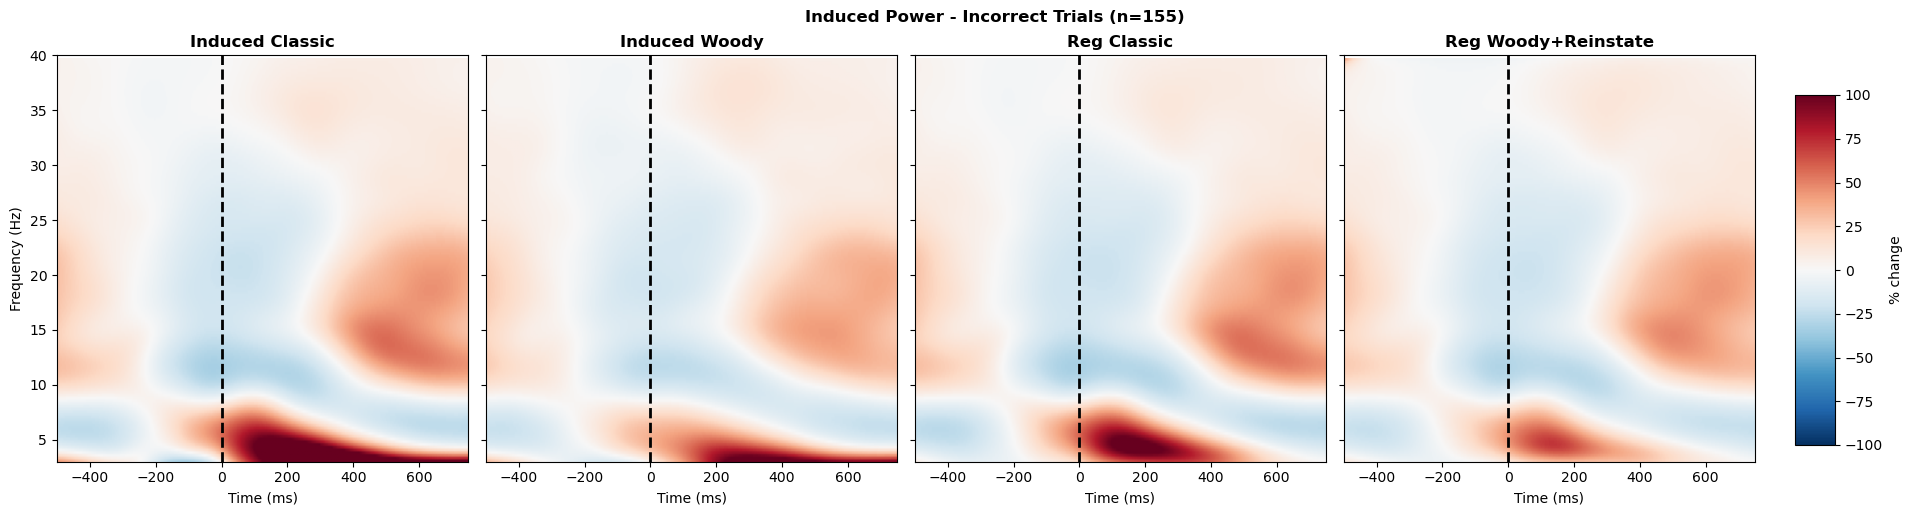

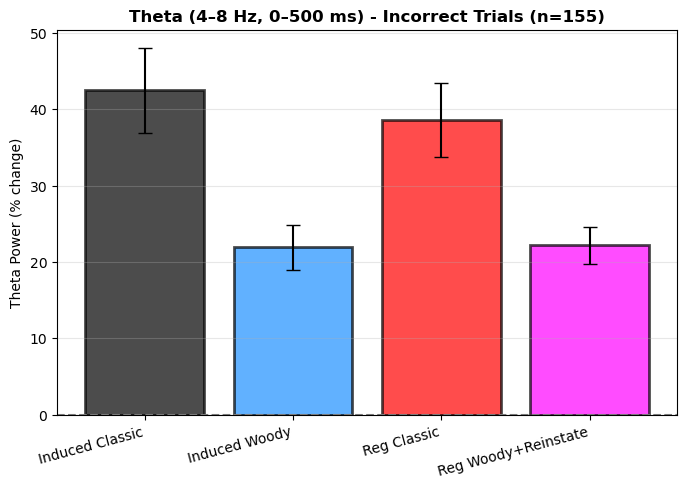

In [64]:
df_incorrect = plot_group_results(results_incorrect, 'Incorrect Trials')

In [81]:
def plot_group_results(results, title_suffix):
    times = results[0]['times']
    freqs = results[0]['freqs']
    n = len(results)

    labels = ['Reg Classic', 'Reg Woody']
    colors = ['red', 'magenta']
    indices = [2, 3]

    def get_bc_tfr(r, i):
        if i == 2:
            return baseline_correct(r['tfr_reg_classic'], times)
        else:
            return baseline_correct(r['tfr_reg_woody_reinstate'], times)

    # TFRs - 1 row x 2 cols
    fig, axes = plt.subplots(1, 2, figsize=(10, 5), sharex=True, sharey=True)
    for ax, label, i in zip(axes, labels, indices):
        m = np.array([get_bc_tfr(r, i) for r in results]).mean(0)
        im = ax.imshow(m, aspect='auto', origin='lower',
                       extent=[times[0]*1000, times[-1]*1000, freqs[0], freqs[-1]],
                       vmin=-100, vmax=100, cmap='RdBu_r')
        ax.axvline(0, color='k', ls='--', lw=2)
        ax.set_xlim(-500, 750)
        ax.set_ylim(3, 40)
        ax.set_title(label, fontweight='bold')
        ax.set_xlabel('Time (ms)')
    axes[0].set_ylabel('Frequency (Hz)')
    plt.tight_layout()
    fig.subplots_adjust(right=0.88)
    cbar_ax = fig.add_axes([0.90, 0.15, 0.02, 0.7])
    fig.colorbar(im, cax=cbar_ax, label='% change')
    plt.suptitle(f'Induced Power - {title_suffix} (n={n})', fontweight='bold', y=1.02)

    # Theta bars
    df = pd.DataFrame([
        {label: extract_theta(get_bc_tfr(r, i), freqs, times)
         for i, label in zip(indices, labels)}
        for r in results
    ])

    fig, ax = plt.subplots(figsize=(5, 5))
    means = df.mean()
    sems  = df.sem()
    ax.bar(range(2), means, yerr=sems, color=colors, alpha=0.7, edgecolor='k', lw=2, capsize=5)
    ax.set_xticks(range(2))
    ax.set_xticklabels(labels, rotation=15, ha='right')
    ax.axhline(0, color='gray', ls='--')
    ax.set_ylabel('Theta Power (% change)')
    ax.set_title(f'Theta (4–8 Hz, 0–500 ms) - {title_suffix}', fontweight='bold')
    ax.grid(alpha=0.3, axis='y')

    return df

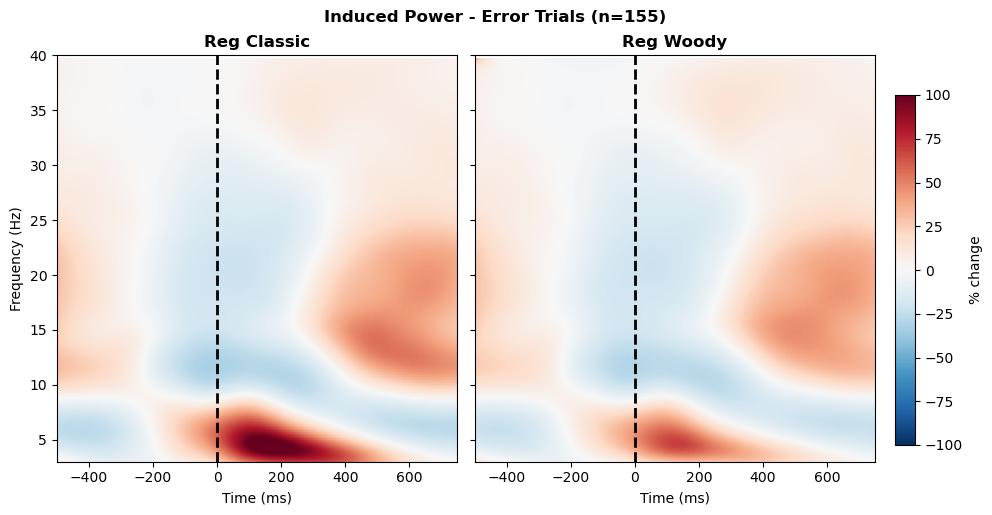

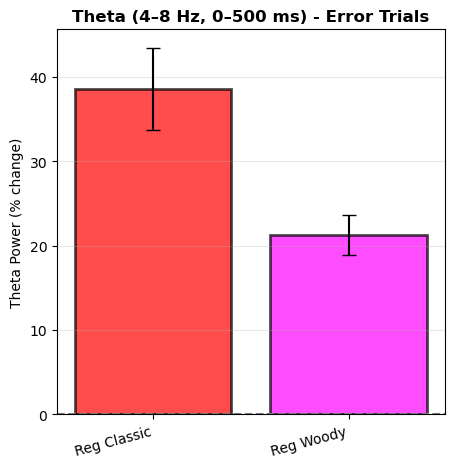

In [82]:
df = plot_group_results(results_incorrect, 'Error Trials')


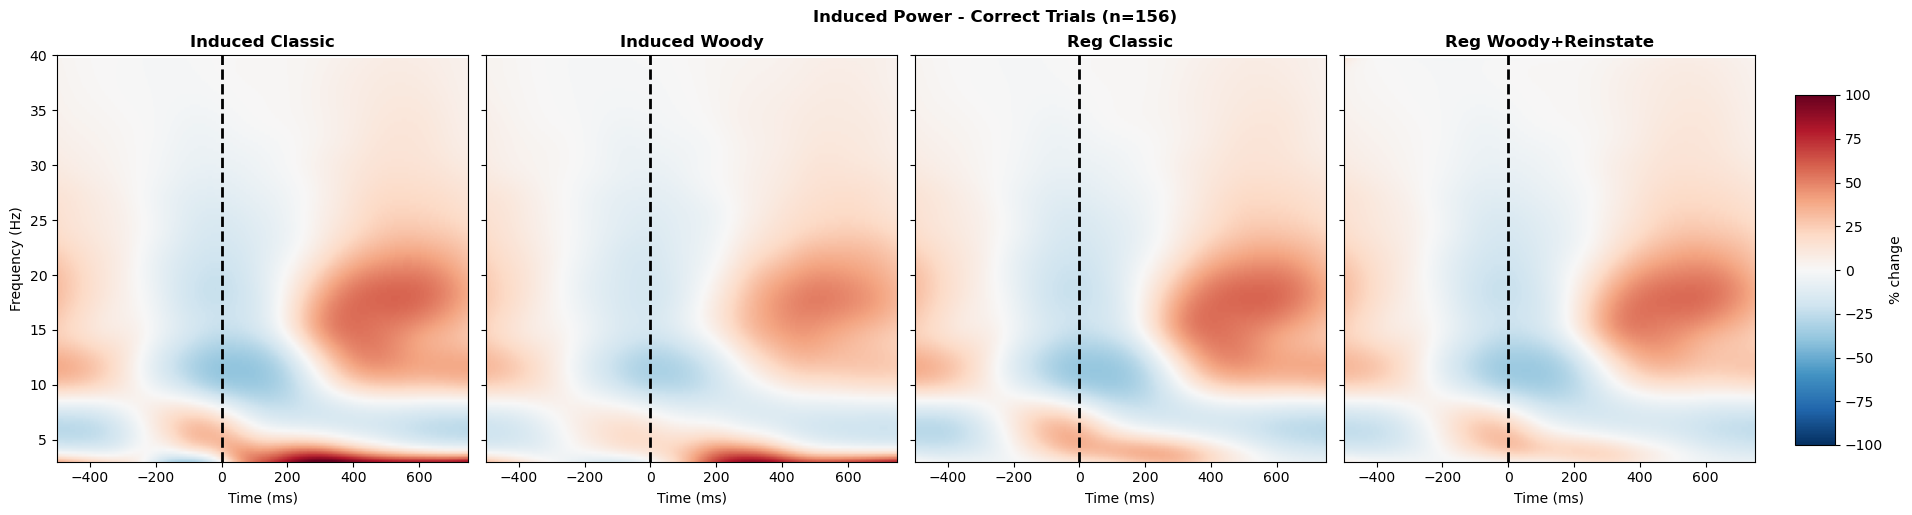

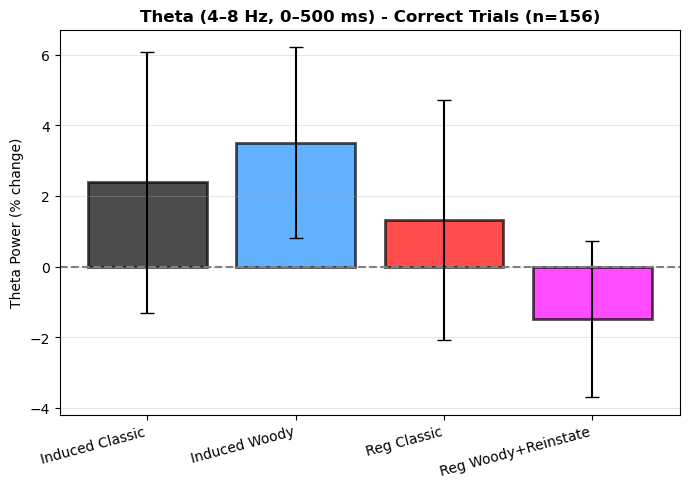

In [65]:
df_correct = plot_group_results(results_correct, 'Correct Trials')

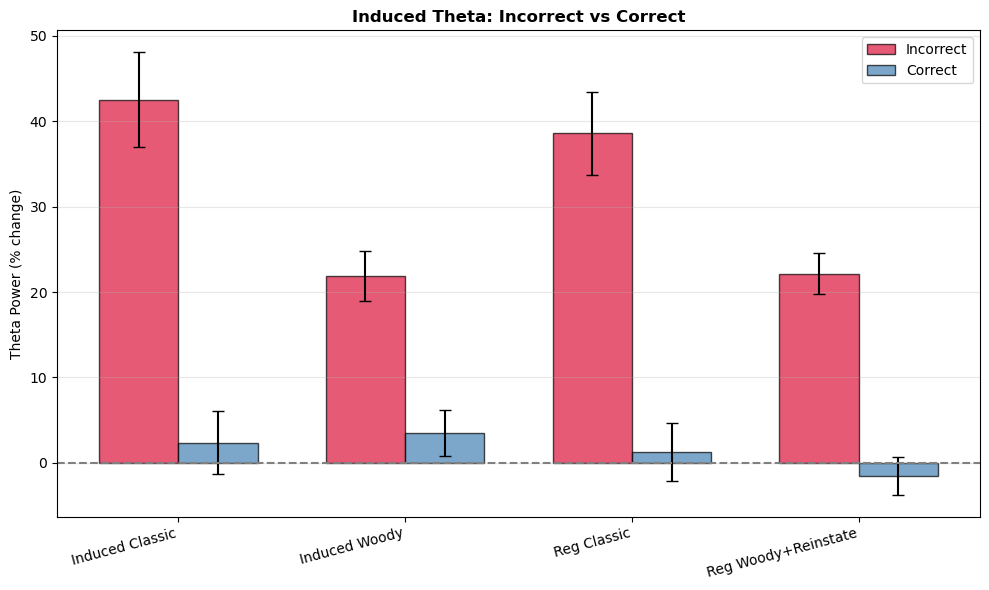

In [71]:
labels    = ['Induced Classic', 'Induced Woody', 'Reg Classic', 'Reg Woody+Reinstate']

colors    = ['black', 'dodgerblue', 'red', 'magenta']

fig, ax = plt.subplots(figsize=(10, 6))
x     = np.arange(4)
width = 0.35

def get_theta_col(df, label):
    return df[label]

means_inc = [df_incorrect[l].mean() for l in labels]
sems_inc  = [df_incorrect[l].sem()  for l in labels]
means_cor = [df_correct[l].mean()   for l in labels]
sems_cor  = [df_correct[l].sem()    for l in labels]

ax.bar(x - width/2, means_inc, width, yerr=sems_inc, label='Incorrect',
       color='crimson', alpha=0.7, edgecolor='k', capsize=4)
ax.bar(x + width/2, means_cor, width, yerr=sems_cor, label='Correct',
       color='steelblue', alpha=0.7, edgecolor='k', capsize=4)

ax.set_xticks(x)
ax.set_xticklabels(labels, rotation=15, ha='right')
ax.axhline(0, color='gray', ls='--')
ax.set_ylabel('Theta Power (% change)')
ax.set_title('Induced Theta: Incorrect vs Correct', fontweight='bold')
ax.legend()
ax.grid(alpha=0.3, axis='y')
plt.tight_layout()

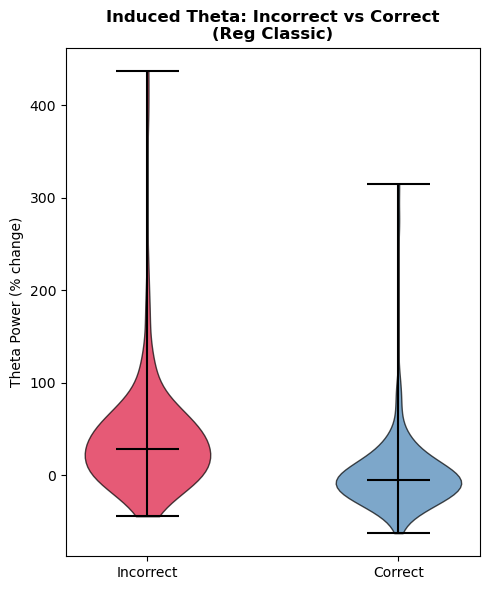

In [74]:
fig, ax = plt.subplots(figsize=(5, 6))

data = [df_incorrect['Reg Classic'].dropna().values,
        df_correct['Reg Classic'].dropna().values]

parts = ax.violinplot(data, positions=[1, 2], showmedians=True, showextrema=True)

colors_viol = ['crimson', 'steelblue']
for pc, color in zip(parts['bodies'], colors_viol):
    pc.set_facecolor(color)
    pc.set_alpha(0.7)
    pc.set_edgecolor('k')

for partname in ('cbars', 'cmins', 'cmaxes', 'cmedians'):
    parts[partname].set_edgecolor('black')
    parts[partname].set_linewidth(1.5)

ax.set_xticks([1, 2])
ax.set_xticklabels(['Incorrect', 'Correct'])
# ax.axhline(0, color='gray', ls='--')
ax.set_ylabel('Theta Power (% change)')
ax.set_title('Induced Theta: Incorrect vs Correct\n(Reg Classic)', fontweight='bold')
# ax.grid(alpha=0.3, axis='y')
plt.tight_layout()

In [9]:
def analyze_lhac(epochs_path, trial_type='incorrect', freqs_range=np.arange(4, 30, 1), lags_range=np.arange(0.5, 5, 0.25)):
    epochs = mne.read_epochs(epochs_path, preload=True, verbose=False)
    
    if trial_type == 'incorrect':
        codes = ['108', '109', '118', '119', '128', '129', '138', '139']
    else:
        codes = ['106', '107', '116', '117', '126', '127', '136', '137']
    
    epochs_sel = epochs[codes]
    n_trials = len(epochs_sel)
    if n_trials < 10:
        return None
    
    data = epochs_sel.copy().pick(['FZ']).get_data()[:, 0, :] * 1e6
    times = epochs_sel.times
    sfreq = epochs_sel.info['sfreq']
    
    time_mask = (times >= -1) & (times <= 1.5)
    data_crop = data[:, time_mask]
    
    # Raw induced
    erp_raw = data_crop.mean(0)
    induced_raw = data_crop - erp_raw
    
    # Stochastic Woody
    _, lags, _ = woody_stochastic(data.T, tol=0.1, max_it=100, n_runs=1000, max_lag_init=10, xcorr_mthd='unbiased', max_shift=50)
    aligned = align_trials(data, lags)
    aligned_crop = aligned[:, time_mask]
    erp_sw = aligned_crop.mean(0)
    induced_sw = aligned_crop - erp_sw
    
    # Stochastic Woody + Regression + Reinstate
    reg_sw = regress_erp(aligned_crop, erp_sw)
    reinstated = reinstate_lags(reg_sw, lags[time_mask] if len(lags) > sum(time_mask) else lags)
    
    lhc_raw = lagged_hilbert_autocoherence(induced_raw, freqs_range, lags_range, srate=sfreq, df=1.0)
    lhc_sw = lagged_hilbert_autocoherence(induced_sw, freqs_range, lags_range, srate=sfreq, df=1.0)
    lhc_sw_reinst = lagged_hilbert_autocoherence(reinstated, freqs_range, lags_range, srate=sfreq, df=1.0)
    
    return {'lhc_raw': lhc_raw, 'lhc_sw': lhc_sw, 'lhc_sw_reinst': lhc_sw_reinst, 'n_trials': n_trials}

In [10]:
freqs_range = np.arange(4, 30, 1)
lags_range = np.arange(0.5, 5, 0.25)

lhac_incorrect = []
lhac_correct = []

for sub_id in tqdm(subjects):
    sub_file = data_dir / sub_id / f'{sub_id}_desc-epochs_eeg.fif'
    if not sub_file.exists():
        continue
    try:
        res_inc = analyze_lhac(sub_file, 'incorrect', freqs_range, lags_range)
        res_cor = analyze_lhac(sub_file, 'correct', freqs_range, lags_range)
        if res_inc:
            lhac_incorrect.append(res_inc)
        if res_cor:
            lhac_correct.append(res_cor)
    except:
        continue

print(f'LHaC - Incorrect: {len(lhac_incorrect)}, Correct: {len(lhac_correct)}')

100%|██████████| 156/156 [4:25:10<00:00, 101.99s/it]  

LHaC - Incorrect: 155, Correct: 156


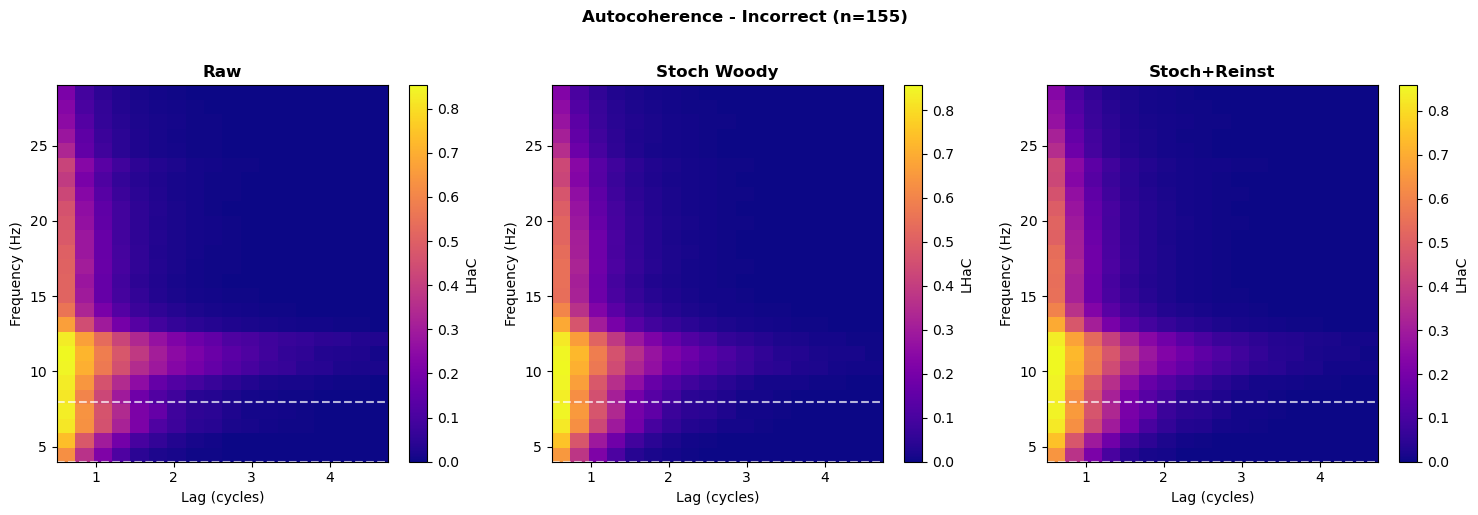

In [11]:
def plot_lhac(results, title_suffix, freqs_range, lags_range):
    lhc_raw = np.array([r['lhc_raw'].mean(0) for r in results]).mean(0)
    lhc_sw = np.array([r['lhc_sw'].mean(0) for r in results]).mean(0)
    lhc_sw_reinst = np.array([r['lhc_sw_reinst'].mean(0) for r in results]).mean(0)
    
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    for ax, lhc, label in zip(axes, [lhc_raw, lhc_sw, lhc_sw_reinst], ['Raw', 'Stoch Woody', 'Stoch+Reinst']):
        im = ax.imshow(lhc, aspect='auto', origin='lower', cmap='plasma',
                       extent=[lags_range[0], lags_range[-1], freqs_range[0], freqs_range[-1]])
        ax.axhline(4, color='w', ls='--', lw=1.5, alpha=0.7)
        ax.axhline(8, color='w', ls='--', lw=1.5, alpha=0.7)
        ax.set_xlabel('Lag (cycles)')
        ax.set_ylabel('Frequency (Hz)')
        ax.set_title(label, fontweight='bold')
        plt.colorbar(im, ax=ax, label='LHaC')
    plt.suptitle(f'Autocoherence - {title_suffix} (n={len(results)})', fontweight='bold', y=1.02)
    plt.tight_layout()

plot_lhac(lhac_incorrect, 'Incorrect', freqs_range, lags_range)

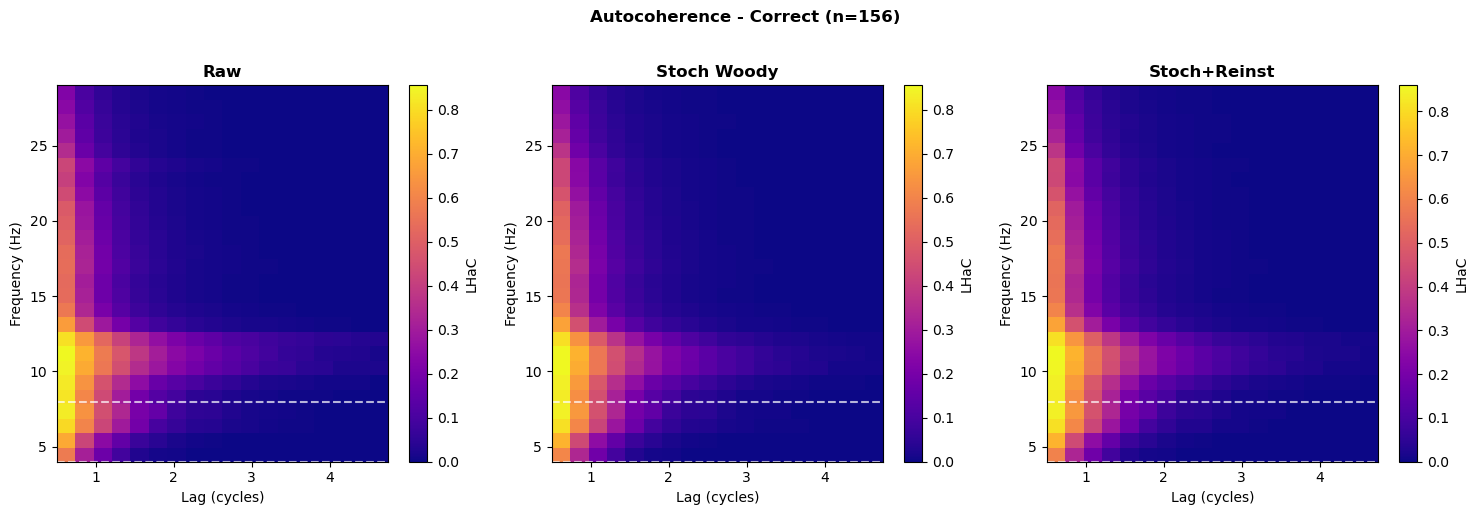

In [12]:
plot_lhac(lhac_correct, 'Correct', freqs_range, lags_range)

In [13]:
df_incorrect.to_csv('theta_analysis_incorrect.csv', index=False)
df_correct.to_csv('theta_analysis_correct.csv', index=False)

In [14]:
from scipy.signal import welch

#TODO check window size and 0 padding

# PSD analysis
psd_incorrect = []
psd_correct = []

for sub_id in tqdm(subjects):
    sub_file = data_dir / sub_id / f'{sub_id}_desc-epochs_eeg.fif'
    if not sub_file.exists():
        continue
    
    try:
        epochs = mne.read_epochs(sub_file, preload=True, verbose=False)
        
        for trial_type in ['incorrect', 'correct']:
            if trial_type == 'incorrect':
                codes = ['108', '109', '118', '119', '128', '129', '138', '139']
            else:
                codes = ['106', '107', '116', '117', '126', '127', '136', '137']
            
            epochs_sel = epochs[codes]
            if len(epochs_sel) < 5:
                continue
            
            data = epochs_sel.copy().pick(['FZ']).get_data()[:, 0, :] * 1e6
            times = epochs_sel.times
            sfreq = epochs_sel.info['sfreq']
            
            pre_mask = (times >= -.5) & (times < 0)
            post_mask = (times >= 0) & (times <= .5)
            
            data_pre = data[:, pre_mask]
            data_post = data[:, post_mask]
            
            # Whole power
            psd_whole_pre = np.array([welch(tr, fs=sfreq, nperseg=int(sfreq))[1] for tr in data_pre]).mean(0)
            psd_whole_post = np.array([welch(tr, fs=sfreq, nperseg=int(sfreq))[1] for tr in data_post]).mean(0)
            freqs = welch(data_pre[0], fs=sfreq, nperseg=int(sfreq))[0]
            
            # Induced raw
            induced_pre = data_pre - data_pre.mean(0)
            induced_post = data_post - data_post.mean(0)
            psd_induced_pre = np.array([welch(tr, fs=sfreq, nperseg=int(sfreq))[1] for tr in induced_pre]).mean(0)
            psd_induced_post = np.array([welch(tr, fs=sfreq, nperseg=int(sfreq))[1] for tr in induced_post]).mean(0)
            
            # Stochastic Woody + Reg + Reinstate
            _, lags, _ = woody_stochastic(data.T, tol=0.1, max_it=100, n_runs=1000, 
                                          max_lag_init=10, xcorr_mthd='unbiased', max_shift=50, verbose=False)
            aligned = align_trials(data, lags)
            erp_aligned = aligned.mean(0)
            regressed = regress_erp(aligned, erp_aligned)
            reinstated = reinstate_lags(regressed, lags)
            
            reinstated_pre = reinstated[:, pre_mask]
            reinstated_post = reinstated[:, post_mask]
            psd_sw_pre = np.array([welch(tr, fs=sfreq, nperseg=int(sfreq))[1] for tr in reinstated_pre]).mean(0)
            psd_sw_post = np.array([welch(tr, fs=sfreq, nperseg=int(sfreq))[1] for tr in reinstated_post]).mean(0)
            
            res = {
                'subject': sub_id, 'freqs': freqs, 'n_trials': len(epochs_sel),
                'psd_whole_pre': psd_whole_pre, 'psd_whole_post': psd_whole_post,
                'psd_induced_pre': psd_induced_pre, 'psd_induced_post': psd_induced_post,
                'psd_sw_pre': psd_sw_pre, 'psd_sw_post': psd_sw_post
            }
            
            if trial_type == 'incorrect':
                psd_incorrect.append(res)
            else:
                psd_correct.append(res)
    except:
        continue



100%|██████████| 156/156 [12:07:12<00:00, 279.70s/it]   


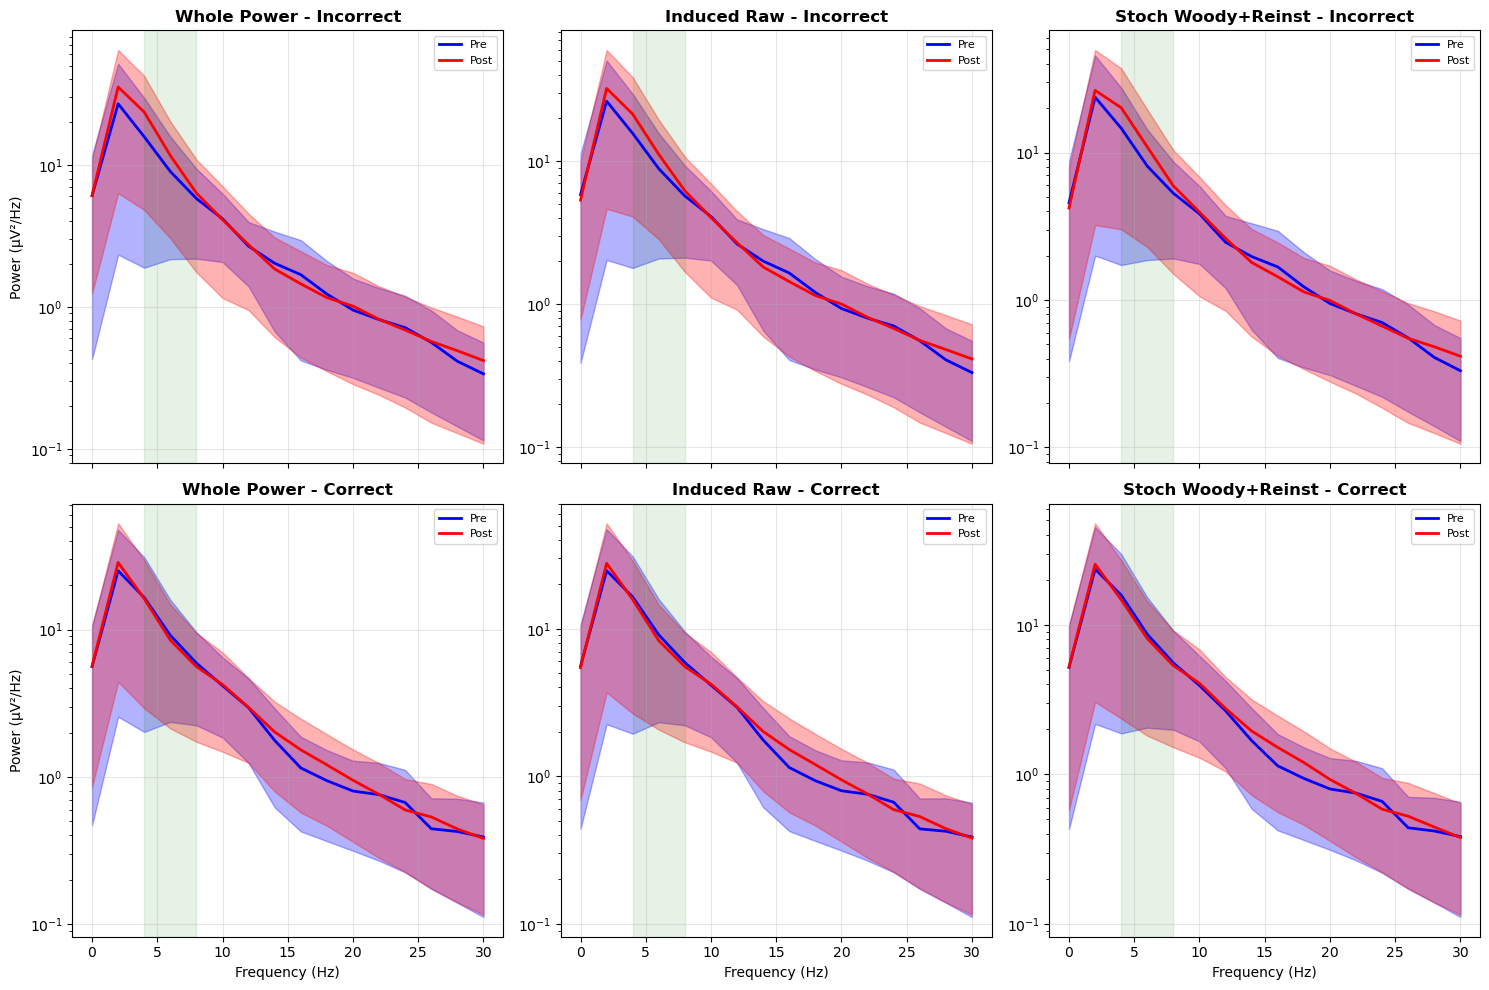

In [15]:
# Plotting - handle different PSD lengths
fig, axes = plt.subplots(2, 3, figsize=(15, 10), sharex=True)

for row, (results, trial_label) in enumerate([(psd_incorrect, 'Incorrect'), (psd_correct, 'Correct')]):
    for col, (key, method_label) in enumerate([('whole', 'Whole Power'), ('induced', 'Induced Raw'), ('sw', 'Stoch Woody+Reinst')]):
        # Get min length across all subjects
        pre_list = [r[f'psd_{key}_pre'] for r in results]
        post_list = [r[f'psd_{key}_post'] for r in results]
        min_len = min(min(len(p) for p in pre_list), min(len(p) for p in post_list))
        
        # Use first subject's freqs truncated to min_len
        freqs = results[0]['freqs'][:min_len]
        freq_mask = freqs <= 30
        
        pre = np.array([p[:min_len] for p in pre_list])[:, freq_mask]
        post = np.array([p[:min_len] for p in post_list])[:, freq_mask]
        
        ax = axes[row, col]
        ax.semilogy(freqs[freq_mask], pre.mean(0), 'b-', lw=2, label='Pre')
        ax.fill_between(freqs[freq_mask], pre.mean(0) - pre.std(0)/np.sqrt(len(pre)),
                        pre.mean(0) + pre.std(0)/np.sqrt(len(pre)), alpha=0.3, color='b')
        ax.semilogy(freqs[freq_mask], post.mean(0), 'r-', lw=2, label='Post')
        ax.fill_between(freqs[freq_mask], post.mean(0) - post.std(0)/np.sqrt(len(post)),
                        post.mean(0) + post.std(0)/np.sqrt(len(post)), alpha=0.3, color='r')
        ax.axvspan(4, 8, alpha=0.1, color='green')
        ax.set_title(f'{method_label} - {trial_label}', fontweight='bold')
        ax.legend(fontsize=8)
        ax.grid(alpha=0.3)
        if row == 1:
            ax.set_xlabel('Frequency (Hz)')
        if col == 0:
            ax.set_ylabel('Power (µV²/Hz)')

plt.tight_layout()
plt.show()

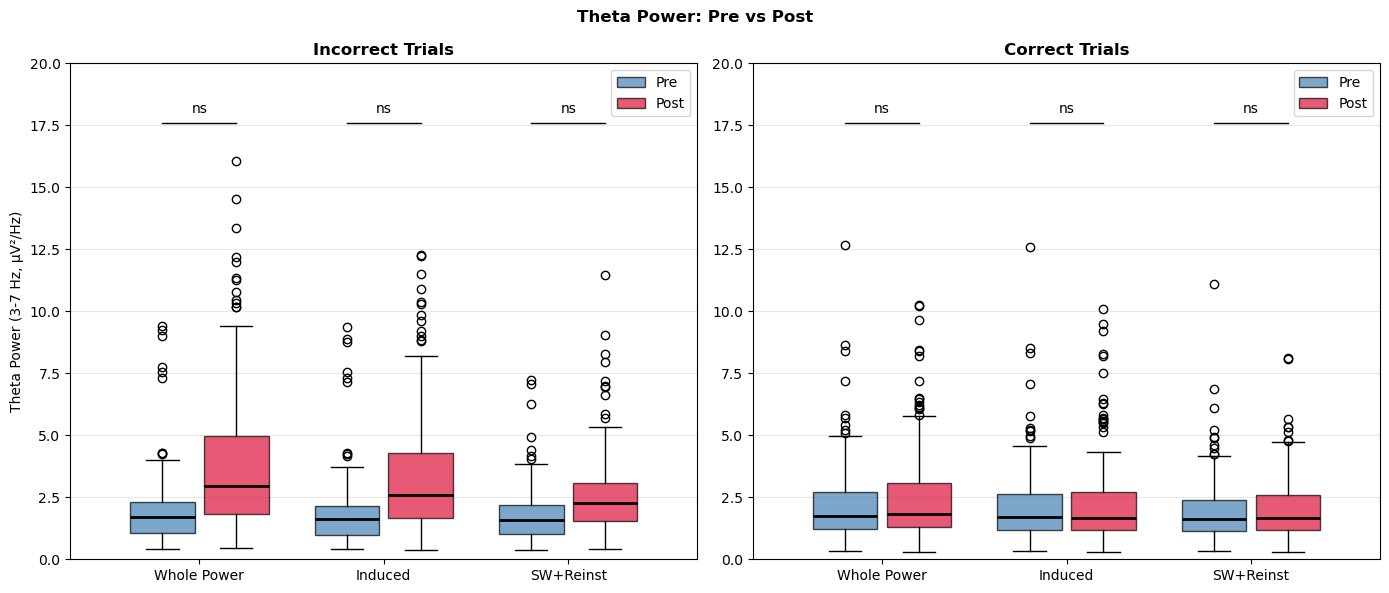


=== T-test Results: Theta Power (Pre vs Post) ===

Incorrect trials:
  Whole Power: Pre=12.375, Post=17.604, t=-1.56, p=0.1197
  Induced: Pre=12.229, Post=16.217, t=-1.61, p=0.1088
  SW+Reinst: Pre=11.351, Post=15.529, t=-1.25, p=0.2119

Correct trials:
  Whole Power: Pre=12.828, Post=12.353, t=0.58, p=0.5648
  Induced: Pre=12.744, Post=12.024, t=0.75, p=0.4566
  SW+Reinst: Pre=12.250, Post=11.427, t=0.87, p=0.3881


In [16]:
from scipy.stats import ttest_rel

methods = ['whole', 'induced', 'sw']
method_labels = ['Whole Power', 'Induced', 'SW+Reinst']

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

ylim_max = 20

for ax, results, title in zip(axes, [psd_incorrect, psd_correct], ['Incorrect', 'Correct']):
    data_pre = []
    data_post = []
    sigs = []
    
    # Get common freq range
    min_len = min(min(len(r[f'psd_whole_pre']) for r in results),
                  min(len(r[f'psd_whole_post']) for r in results))
    freqs = results[0]['freqs'][:min_len]
    theta_mask = (freqs >= 3) & (freqs <= 7)
    
    for i, key in enumerate(methods):
        pre = np.array([r[f'psd_{key}_pre'][:min_len][theta_mask].mean() for r in results])
        post = np.array([r[f'psd_{key}_post'][:min_len][theta_mask].mean() for r in results])
        
        data_pre.append(pre)
        data_post.append(post)
        
        # Paired t-test
        t, p = ttest_rel(pre, post)
        
        if p < 0.001:
            sig = '***'
        elif p < 0.01:
            sig = '**'
        elif p < 0.05:
            sig = '*'
        else:
            sig = 'ns'
        sigs.append(sig)
    
    bp1 = ax.boxplot(data_pre, positions=[i - 0.2 for i in range(3)], widths=0.35, patch_artist=True,
                      boxprops=dict(facecolor='steelblue', alpha=0.7),
                      medianprops=dict(color='black', lw=2))
    bp2 = ax.boxplot(data_post, positions=[i + 0.2 for i in range(3)], widths=0.35, patch_artist=True,
                      boxprops=dict(facecolor='crimson', alpha=0.7),
                      medianprops=dict(color='black', lw=2))
    
    # Add significance using ylim
    for i, sig in enumerate(sigs):
        y_bar = ylim_max * 0.88
        ax.plot([i - 0.2, i + 0.2], [y_bar, y_bar], 'k-', lw=1)
        ax.text(i, y_bar + ylim_max * 0.02, sig, ha='center', fontsize=10)
    
    ax.set_ylim(0, ylim_max)
    ax.set_xticks(range(len(methods)))
    ax.set_xticklabels(method_labels)
    ax.set_title(f'{title} Trials', fontweight='bold')
    ax.legend([bp1['boxes'][0], bp2['boxes'][0]], ['Pre', 'Post'], loc='upper right')
    ax.grid(alpha=0.3, axis='y')

axes[0].set_ylabel('Theta Power (3-7 Hz, µV²/Hz)')
plt.suptitle('Theta Power: Pre vs Post', fontweight='bold')
plt.tight_layout()
plt.show()

# Print stats
print("\n=== T-test Results: Theta Power (Pre vs Post) ===")
for title, results in [('Incorrect', psd_incorrect), ('Correct', psd_correct)]:
    min_len = min(min(len(r[f'psd_whole_pre']) for r in results),
                  min(len(r[f'psd_whole_post']) for r in results))
    freqs = results[0]['freqs'][:min_len]
    theta_mask = (freqs >= 3) & (freqs <= 7)
    
    print(f"\n{title} trials:")
    for key, label in zip(methods, method_labels):
        pre = np.array([r[f'psd_{key}_pre'][:min_len][theta_mask].mean() for r in results])
        post = np.array([r[f'psd_{key}_post'][:min_len][theta_mask].mean() for r in results])
        t, p = ttest_rel(pre, post)
        print(f"  {label}: Pre={pre.mean():.3f}, Post={post.mean():.3f}, t={t:.2f}, p={p:.4f}")

In [17]:
from specparam import SpectralModel

sp_settings = {'peak_width_limits': [2, 8], 'max_n_peaks': 6, 'min_peak_height': 0.1}

specparam_incorrect = []
specparam_correct = []

for sub_id in tqdm(subjects):
    sub_file = data_dir / sub_id / f'{sub_id}_desc-epochs_eeg.fif'
    if not sub_file.exists():
        continue
    
    try:
        epochs = mne.read_epochs(sub_file, preload=True, verbose=False)
        
        for trial_type in ['incorrect', 'correct']:
            if trial_type == 'incorrect':
                codes = ['108', '109', '118', '119', '128', '129', '138', '139']
            else:
                codes = ['106', '107', '116', '117', '126', '127', '136', '137']
            
            epochs_sel = epochs[codes]
            if len(epochs_sel) < 5:
                continue
            
            data = epochs_sel.copy().pick(['FZ']).get_data()[:, 0, :] * 1e6
            times = epochs_sel.times
            sfreq = epochs_sel.info['sfreq']
            
            pre_mask = (times >= -.5) & (times < 0)
            post_mask = (times >= 0) & (times <= .5)
            
            data_pre = data[:, pre_mask]
            data_post = data[:, post_mask]
            
            # Stochastic Woody + Reg + Reinstate
            _, lags, _ = woody_stochastic(data.T, tol=0.1, max_it=100, n_runs=100,
                                          max_lag_init=10, xcorr_mthd='unbiased', max_shift=50,
                                          verbose=False)
            aligned = align_trials(data, lags)
            erp_aligned = aligned.mean(0)
            regressed = regress_erp(aligned, erp_aligned)
            reinstated = reinstate_lags(regressed, lags)
            
            reinstated_pre = reinstated[:, pre_mask]
            reinstated_post = reinstated[:, post_mask]
            
            induced_pre = data_pre - data_pre.mean(0)
            induced_post = data_post - data_post.mean(0)
            
            res = {'subject': sub_id, 'n_trials': len(epochs_sel)}
            
            for method, (d_pre, d_post) in [('whole', (data_pre, data_post)),
                                             ('induced', (induced_pre, induced_post)),
                                             ('sw', (reinstated_pre, reinstated_post))]:
                for window, d in [('pre', d_pre), ('post', d_post)]:
                    psd_trials = np.array([welch(tr, fs=sfreq, nperseg=int(sfreq))[1] for tr in d])
                    freqs = welch(d[0], fs=sfreq, nperseg=int(sfreq))[0]
                    psd_mean = psd_trials.mean(0)
                    
                    sm = SpectralModel(**sp_settings, verbose=False)
                    sm.fit(freqs, psd_mean, [1, 30])
                    
                    # Store
                    res[f'{method}_{window}_psd'] = psd_mean
                    res[f'{method}_{window}_flat'] = sm.results.model._spectrum_flat  # 1/f removed
                    res[f'{method}_{window}_ap_fit'] = sm.results.model._ap_fit  # aperiodic fit
                    res['freqs_fit'] = sm.data.freqs  # fit range freqs
                    res['freqs'] = freqs
                    
                    ap = sm.results.params.aperiodic.params
                    res[f'{method}_{window}_offset'] = ap[0]
                    res[f'{method}_{window}_exp'] = ap[1]
                    res[f'{method}_{window}_r2'] = sm.results.metrics.get_metrics('gof')
                    
                    peaks = sm.results.params.periodic.params
                    if peaks is not None and len(peaks) > 0:
                        peaks = np.atleast_2d(peaks)
                        cfs = peaks[:, 0]
                        pws = peaks[:, 1]
                        theta_idx = np.where((cfs >= 4) & (cfs <= 8))[0]
                        if len(theta_idx) > 0:
                            best = theta_idx[np.argmax(pws[theta_idx])]
                            res[f'{method}_{window}_theta_cf'] = cfs[best]
                            res[f'{method}_{window}_theta_pw'] = pws[best]
                        else:
                            res[f'{method}_{window}_theta_cf'] = np.nan
                            res[f'{method}_{window}_theta_pw'] = np.nan
                    else:
                        res[f'{method}_{window}_theta_cf'] = np.nan
                        res[f'{method}_{window}_theta_pw'] = np.nan
            
            if trial_type == 'incorrect':
                specparam_incorrect.append(res)
            else:
                specparam_correct.append(res)
    except Exception as e:
        print(f"Error {sub_id}: {e}")
        continue

print(f'Specparam - Incorrect: {len(specparam_incorrect)}, Correct: {len(specparam_correct)}')

100%|██████████| 156/156 [08:29<00:00,  3.26s/it]

Specparam - Incorrect: 155, Correct: 156


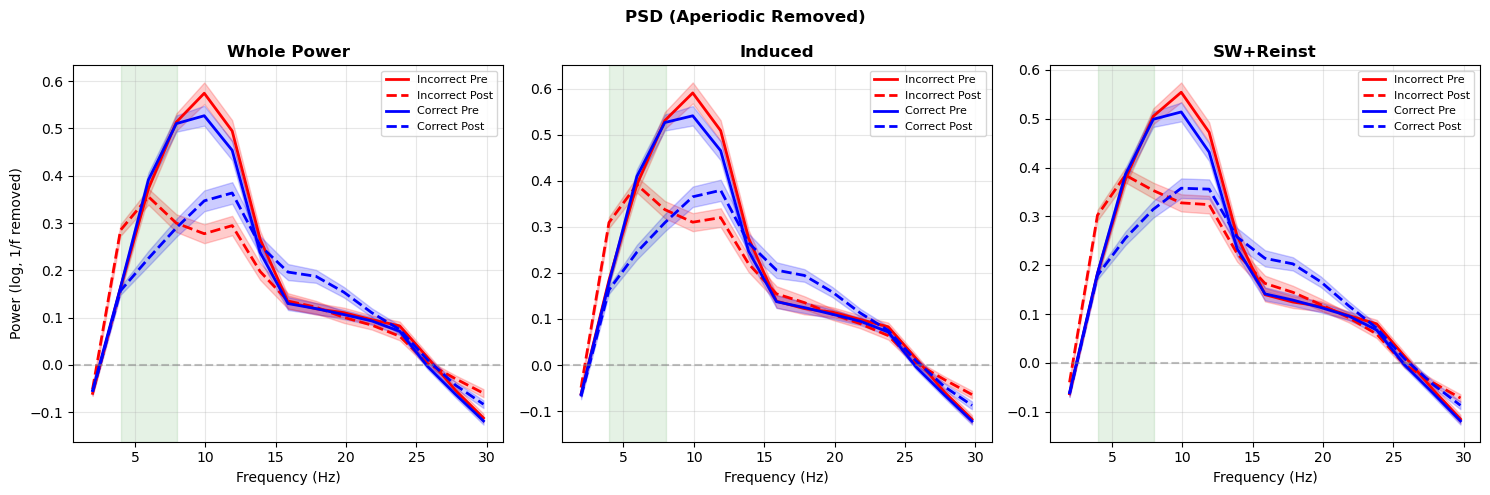

In [18]:
freqs_fit = specparam_incorrect[0]['freqs_fit']
methods = ['whole', 'induced', 'sw']
method_labels = ['Whole Power', 'Induced', 'SW+Reinst']

# 1. Flattened PSD (1/f removed)
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, method, label in zip(axes, methods, method_labels):
    inc_pre = np.array([r[f'{method}_pre_flat'] for r in specparam_incorrect])
    inc_post = np.array([r[f'{method}_post_flat'] for r in specparam_incorrect])
    cor_pre = np.array([r[f'{method}_pre_flat'] for r in specparam_correct])
    cor_post = np.array([r[f'{method}_post_flat'] for r in specparam_correct])
    
    ax.plot(freqs_fit, inc_pre.mean(0), 'r-', lw=2, label='Incorrect Pre')
    ax.fill_between(freqs_fit, inc_pre.mean(0) - inc_pre.std(0)/np.sqrt(len(inc_pre)),
                    inc_pre.mean(0) + inc_pre.std(0)/np.sqrt(len(inc_pre)), color='r', alpha=0.2)
    ax.plot(freqs_fit, inc_post.mean(0), 'r--', lw=2, label='Incorrect Post')
    ax.fill_between(freqs_fit, inc_post.mean(0) - inc_post.std(0)/np.sqrt(len(inc_post)),
                    inc_post.mean(0) + inc_post.std(0)/np.sqrt(len(inc_post)), color='r', alpha=0.2)
    ax.plot(freqs_fit, cor_pre.mean(0), 'b-', lw=2, label='Correct Pre')
    ax.fill_between(freqs_fit, cor_pre.mean(0) - cor_pre.std(0)/np.sqrt(len(cor_pre)),
                    cor_pre.mean(0) + cor_pre.std(0)/np.sqrt(len(cor_pre)), color='b', alpha=0.2)
    ax.plot(freqs_fit, cor_post.mean(0), 'b--', lw=2, label='Correct Post')
    ax.fill_between(freqs_fit, cor_post.mean(0) - cor_post.std(0)/np.sqrt(len(cor_post)),
                    cor_post.mean(0) + cor_post.std(0)/np.sqrt(len(cor_post)), color='b', alpha=0.2)
    
    ax.axvspan(4, 8, alpha=0.1, color='green')
    ax.axhline(0, color='gray', ls='--', alpha=0.5)
    ax.set_xlabel('Frequency (Hz)')
    ax.set_title(label, fontweight='bold')
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)

axes[0].set_ylabel('Power (log, 1/f removed)')
plt.suptitle('PSD (Aperiodic Removed)', fontweight='bold')
plt.tight_layout()

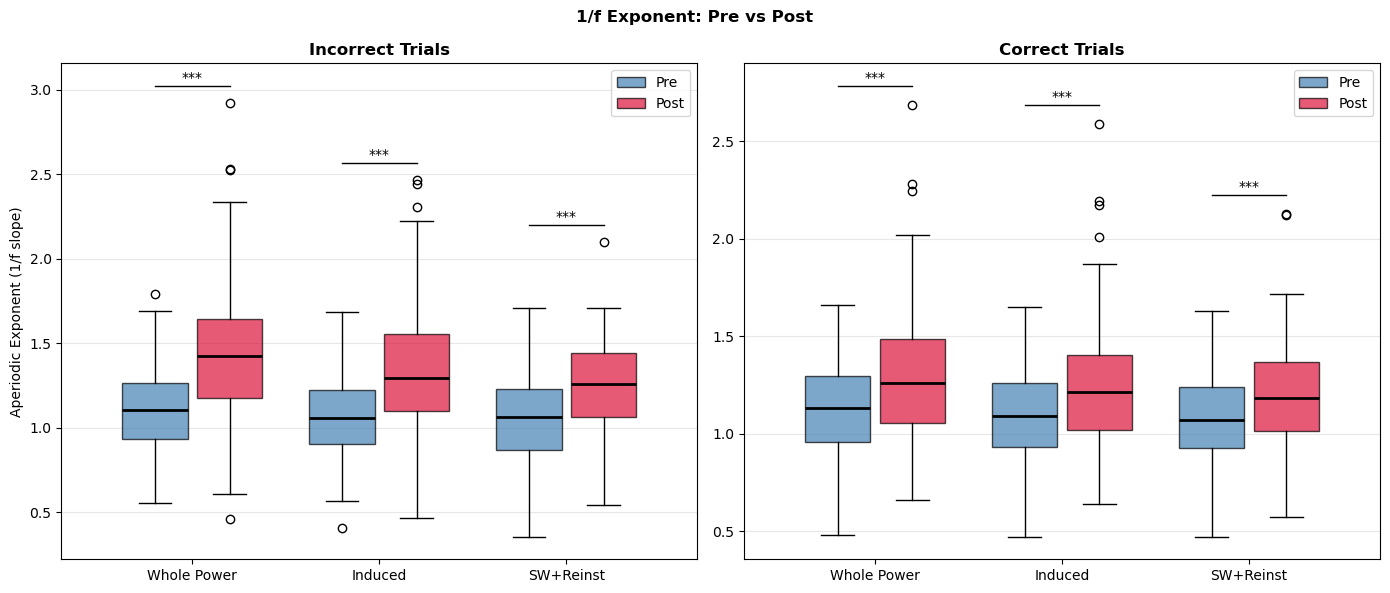


=== T-test Results (Pre vs Post) ===

Incorrect trials:
  Whole Power: Pre=1.103, Post=1.432, t=-12.56, p=0.0000
  Induced: Pre=1.060, Post=1.345, t=-11.78, p=0.0000
  SW+Reinst: Pre=1.056, Post=1.251, t=-12.19, p=0.0000

Correct trials:
  Whole Power: Pre=1.129, Post=1.285, t=-8.15, p=0.0000
  Induced: Pre=1.092, Post=1.231, t=-7.47, p=0.0000
  SW+Reinst: Pre=1.079, Post=1.193, t=-8.28, p=0.0000


In [19]:
from scipy.stats import ttest_rel

df_sp_inc = pd.DataFrame(specparam_incorrect)
df_sp_cor = pd.DataFrame(specparam_correct)

methods = ['whole', 'induced', 'sw']
method_labels = ['Whole Power', 'Induced', 'SW+Reinst']

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, df, title in zip(axes, [df_sp_inc, df_sp_cor], ['Incorrect', 'Correct']):
    data_pre = []
    data_post = []
    positions_pre = []
    positions_post = []
    
    for i, m in enumerate(methods):
        pre = df[f'{m}_pre_exp'].dropna()
        post = df[f'{m}_post_exp'].dropna()
        
        data_pre.append(pre.values)
        data_post.append(post.values)
        positions_pre.append(i - 0.2)
        positions_post.append(i + 0.2)
        
        # Paired t-test
        common = df[[f'{m}_pre_exp', f'{m}_post_exp']].dropna()
        t, p = ttest_rel(common[f'{m}_pre_exp'], common[f'{m}_post_exp'])
        
        # Significance stars
        if p < 0.001:
            sig = '***'
        elif p < 0.01:
            sig = '**'
        elif p < 0.05:
            sig = '*'
        else:
            sig = 'ns'
        
        y_max = max(pre.max(), post.max()) + 0.1
        ax.plot([i - 0.2, i + 0.2], [y_max, y_max], 'k-', lw=1)
        ax.text(i, y_max + 0.02, sig, ha='center', fontsize=10)
    
    bp1 = ax.boxplot(data_pre, positions=positions_pre, widths=0.35, patch_artist=True,
                      boxprops=dict(facecolor='steelblue', alpha=0.7),
                      medianprops=dict(color='black', lw=2))
    bp2 = ax.boxplot(data_post, positions=positions_post, widths=0.35, patch_artist=True,
                      boxprops=dict(facecolor='crimson', alpha=0.7),
                      medianprops=dict(color='black', lw=2))
    
    ax.set_xticks(range(len(methods)))
    ax.set_xticklabels(method_labels)
    ax.set_title(f'{title} Trials', fontweight='bold')
    ax.legend([bp1['boxes'][0], bp2['boxes'][0]], ['Pre', 'Post'], loc='upper right')
    ax.grid(alpha=0.3, axis='y')

axes[0].set_ylabel('Aperiodic Exponent (1/f slope)')
plt.suptitle('1/f Exponent: Pre vs Post', fontweight='bold')
plt.tight_layout()
plt.show()

# Print stats
print("\n=== T-test Results (Pre vs Post) ===")
for title, df in [('Incorrect', df_sp_inc), ('Correct', df_sp_cor)]:
    print(f"\n{title} trials:")
    for m, label in zip(methods, method_labels):
        common = df[[f'{m}_pre_exp', f'{m}_post_exp']].dropna()
        t, p = ttest_rel(common[f'{m}_pre_exp'], common[f'{m}_post_exp'])
        pre_m = common[f'{m}_pre_exp'].mean()
        post_m = common[f'{m}_post_exp'].mean()
        print(f"  {label}: Pre={pre_m:.3f}, Post={post_m:.3f}, t={t:.2f}, p={p:.4f}")